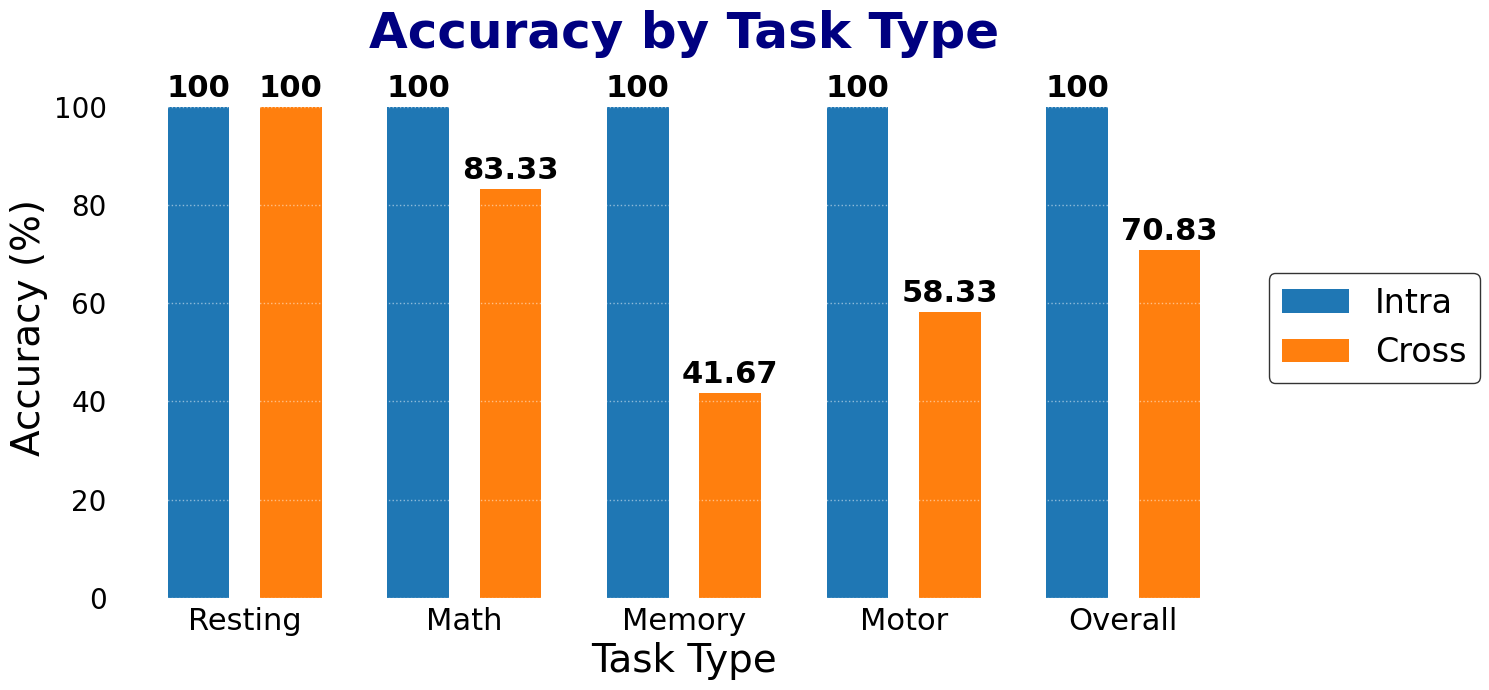

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

output_dir = "./Output"

# File paths
intra_path = rf"{output_dir}\Intra\test_metrics_MultiviewAttention_intra_20250601_225149.csv"
cross_path = rf"{output_dir}\Cross\test_metrics_MultiviewAttention_cross_20250601_122704.csv"#\test_metrics_MultiviewAttention_cross_20250528_231723.csv"

# Load files
df_intra = pd.read_csv(intra_path)
df_cross = pd.read_csv(cross_path)

# Task mapping
task_map = {0: "Resting", 1: "Math", 2: "Memory", 3: "Motor"}

# Intra accuracies from predictions
df_intra["task"] = df_intra["y_true"].map(task_map)
intra_accuracies = {}
for task in task_map.values():
    task_df = df_intra[df_intra["task"] == task]
    correct = (task_df["y_true"] == task_df["y_pred"]).sum()
    accuracy = correct / len(task_df) if len(task_df) > 0 else 0
    intra_accuracies[task] = accuracy
intra_accuracies["Overall"] = (df_intra["y_true"] == df_intra["y_pred"]).mean()

# Cross accuracies from predictions
df_cross["task"] = df_cross["y_true"].map(task_map)
cross_accuracies = {}
for task in task_map.values():
    task_df = df_cross[df_cross["task"] == task]
    correct = (task_df["y_true"] == task_df["y_pred"]).sum()
    accuracy = correct / len(task_df) if len(task_df) > 0 else 0
    cross_accuracies[task] = accuracy
cross_accuracies["Overall"] = (df_cross["y_true"] == df_cross["y_pred"]).mean()

# Prepare data for plotting
tasks = ["Resting", "Math", "Memory", "Motor", "Overall"]
intra_vals = [intra_accuracies[t] * 100 for t in tasks]
cross_vals = [cross_accuracies[t] * 100 for t in tasks]

x = np.arange(len(tasks))
group_width = 0.7  # total width for each group
bar_width = 0.28   # width of each bar
gap = 0.14         # gap between bars in a group

plt.figure(figsize=(15, 7), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

intra_color = '#1f77b4'  # blue
cross_color = '#ff7f0e'  # orange

# Calculate positions for intra and cross bars
intra_pos = x - (bar_width/2 + gap/2)
cross_pos = x + (bar_width/2 + gap/2)

bars1 = plt.bar(intra_pos, intra_vals, bar_width, label='Intra', color=intra_color)
bars2 = plt.bar(cross_pos, cross_vals, bar_width, label='Cross', color=cross_color)

# Add labels on bars, show integer if value is exactly 100, else two decimals
for i in range(len(tasks)):
    intra_label = f"{int(intra_vals[i])}" if np.isclose(intra_vals[i], 100) else f"{intra_vals[i]:.2f}"
    cross_label = f"{int(cross_vals[i])}" if np.isclose(cross_vals[i], 100) else f"{cross_vals[i]:.2f}"
    plt.text(intra_pos[i], intra_vals[i] + 2, intra_label, 
             ha='center', fontsize=22, color='black', weight='bold')
    plt.text(cross_pos[i], cross_vals[i] + 2, cross_label, 
             ha='center', fontsize=22, color='black', weight='bold')

plt.title("Accuracy by Task Type", fontsize=36, weight='bold', color='navy')
plt.xlabel("Task Type", fontsize=28, color='black')
plt.ylabel("Accuracy (%)", fontsize=28, color='black')
plt.xticks(x, tasks, fontsize=22, color='black')
plt.yticks(fontsize=20, color='black')
plt.ylim(0, 110)

# Add grid lines for better readability
plt.grid(axis='y', linestyle=':', linewidth=1, alpha=0.5)
plt.grid(axis='x', linestyle='-', linewidth=1, alpha=0.5)  # <-- Add vertical grid lines



# Legend with white background and black text, to the right
legend = plt.legend(fontsize=24, loc='center left', bbox_to_anchor=(1, 0.5), frameon=True)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_edgecolor('black')
for text in legend.get_texts():
    text.set_color('black')

plt.tight_layout()
plt.savefig(rf"{output_dir}\Cross_Vs_Intra.png", dpi=300, bbox_inches='tight')
plt.show()

In [99]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_metric_heatmaps_by_parameters(df, parameters, metric="accuracy", cmap="Blues"):
    ncols = 4
    nrows = (len(parameters) + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 6 * nrows), facecolor='white')
    axes = axes.flatten()

    # Set main figure title
    fig.suptitle("Accuracy by Hyperparameters", fontsize=28, weight='bold', color='darkblue', y=1)

    for i, param in enumerate(parameters):
        ax = axes[i]
        ax.set_facecolor('white')

        if df[param].dtype == "float64":
            df[param] = df[param].round(4)

        task_cols = [col for col in df.columns if col.startswith("val_") and col.endswith(f"_{metric}")]
        if not task_cols:
            ax.set_title(f"No test {metric} columns found", color='red', fontsize=18)
            ax.axis("off")
            continue

        grouped = df[[param] + task_cols].groupby(param).mean()
        renamed = grouped.rename(columns=lambda col: col.split("_")[1])
        transposed = renamed.transpose()

        ax = sns.heatmap(
            transposed,
            ax=ax,
            cmap=cmap,
            cbar=True,
            linewidths=0.8,
            linecolor="white",
            cbar_kws={"label": f"{metric.capitalize()} (%)"}
        )
        cbar = ax.collections[0].colorbar
        cbar.ax.yaxis.label.set_size(22)
        cbar.ax.tick_params(labelsize=18, colors='black')
        cbar.outline.set_edgecolor('black')

        # Only parameter name in subplot title
        ax.set_title(param.replace('_', ' ').title(), fontsize=20, weight='bold', color='indigo')
        ax.set_xlabel("Value", fontsize=22, color='navy', weight='bold',)
        ax.set_ylabel("Task Type", fontsize=22, color='navy', weight='bold',)
        ax.tick_params(axis='both', labelsize=20, colors='black')

        # Rotate x-tick labels more and reduce font size for clarity
        ax.set_xticklabels(ax.get_xticklabels(), rotation=75, ha='right', fontsize=16, color='black')
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=20, color='black')

        # Optionally, show only every Nth label if too many
        if len(ax.get_xticklabels()) > 20:
            for idx, label in enumerate(ax.get_xticklabels()):
                if idx % 2 != 0:
                    label.set_visible(False)

    for j in range(len(parameters), len(axes)):
        fig.delaxes(axes[j])

    plt.subplots_adjust(wspace=0.3, hspace=0.3, top=0.90)
    plt.tight_layout()
    plt.savefig(rf"{output_dir}\Hyperparameter_Heatmaps.png", dpi=300, bbox_inches='tight')
    plt.show()

Index(['trial_id', 'epoch', 'train_overall_accuracy', 'train_overall_F1',
       'train_overall_recall', 'train_overall_precision',
       'train_resting_accuracy', 'train_resting_F1', 'train_resting_recall',
       'train_resting_precision', 'train_math_accuracy', 'train_math_F1',
       'train_math_recall', 'train_math_precision', 'train_memory_accuracy',
       'train_memory_F1', 'train_memory_recall', 'train_memory_precision',
       'train_motor_accuracy', 'train_motor_F1', 'train_motor_recall',
       'train_motor_precision', 'val_overall_accuracy', 'val_overall_F1',
       'val_overall_recall', 'val_overall_precision', 'val_resting_accuracy',
       'val_resting_F1', 'val_resting_recall', 'val_resting_precision',
       'val_math_accuracy', 'val_math_F1', 'val_math_recall',
       'val_math_precision', 'val_memory_accuracy', 'val_memory_F1',
       'val_memory_recall', 'val_memory_precision', 'val_motor_accuracy',
       'val_motor_F1', 'val_motor_recall', 'val_motor_precision',

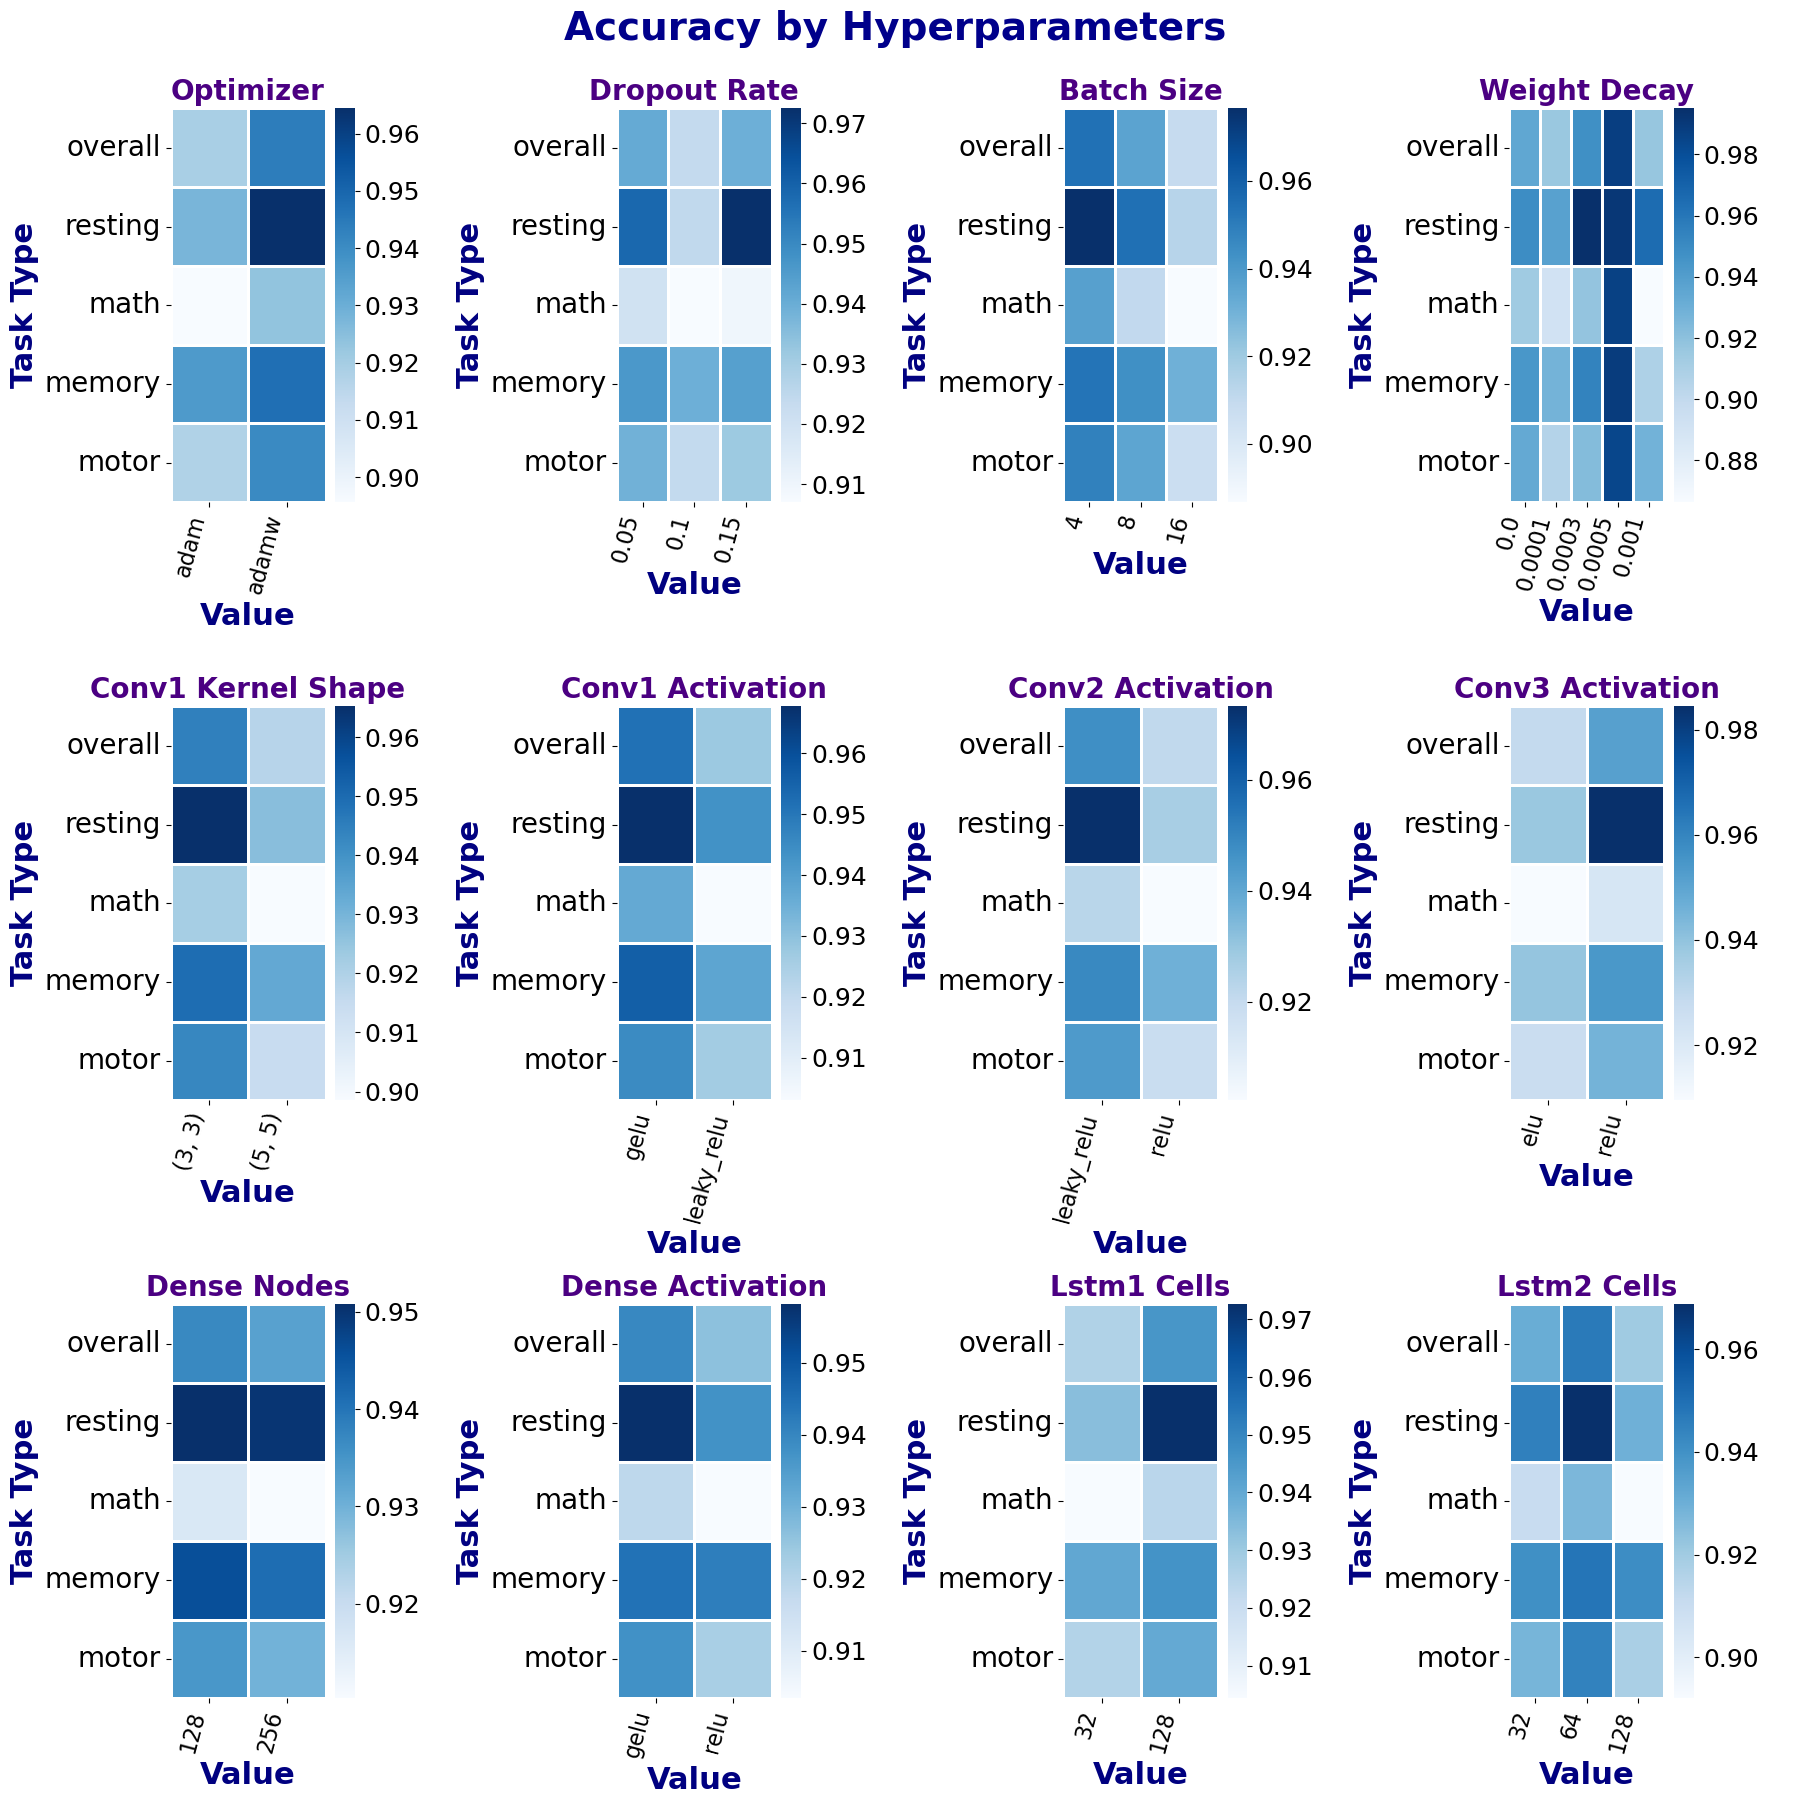

In [100]:
# Usage
all_metrics_df = pd.read_csv(rf"{output_dir}\Cross\best_model_MultiviewAttention_cross_20250531_195521.csv")#best_model_MultiviewAttention_cross_20250601_122704.csv")

print(all_metrics_df.columns)

# parameters_to_plot = ["learning_rate", "dropout_rate", "batch_size"]

parameters_to_plot = [
    'optimizer',
    'dropout_rate',
    'batch_size',
    'weight_decay',
    'conv1_kernel_shape',
    'conv1_activation',
    'conv2_activation',
    'conv3_activation',
    'dense_nodes',
    'dense_activation',
    'lstm1_cells',
    'lstm2_cells',
#     'dense3_nodes',
#     'dense3_activation'
]
plot_metric_heatmaps_by_parameters(all_metrics_df, parameters_to_plot, metric="accuracy")

C:\Users\bar24\AppData\Local\Temp\ipykernel_4964\1211830740.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  overall_acc_per_task = df.groupby('y_true').apply(lambda x: (x['y_true'] == x['y_pred']).mean())
C:\Users\bar24\AppData\Local\Temp\ipykernel_4964\1211830740.py:38: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_patient_acc = df.groupby(['patient_id', 'y_true']).apply(lambda x: (x['y_true'] == 

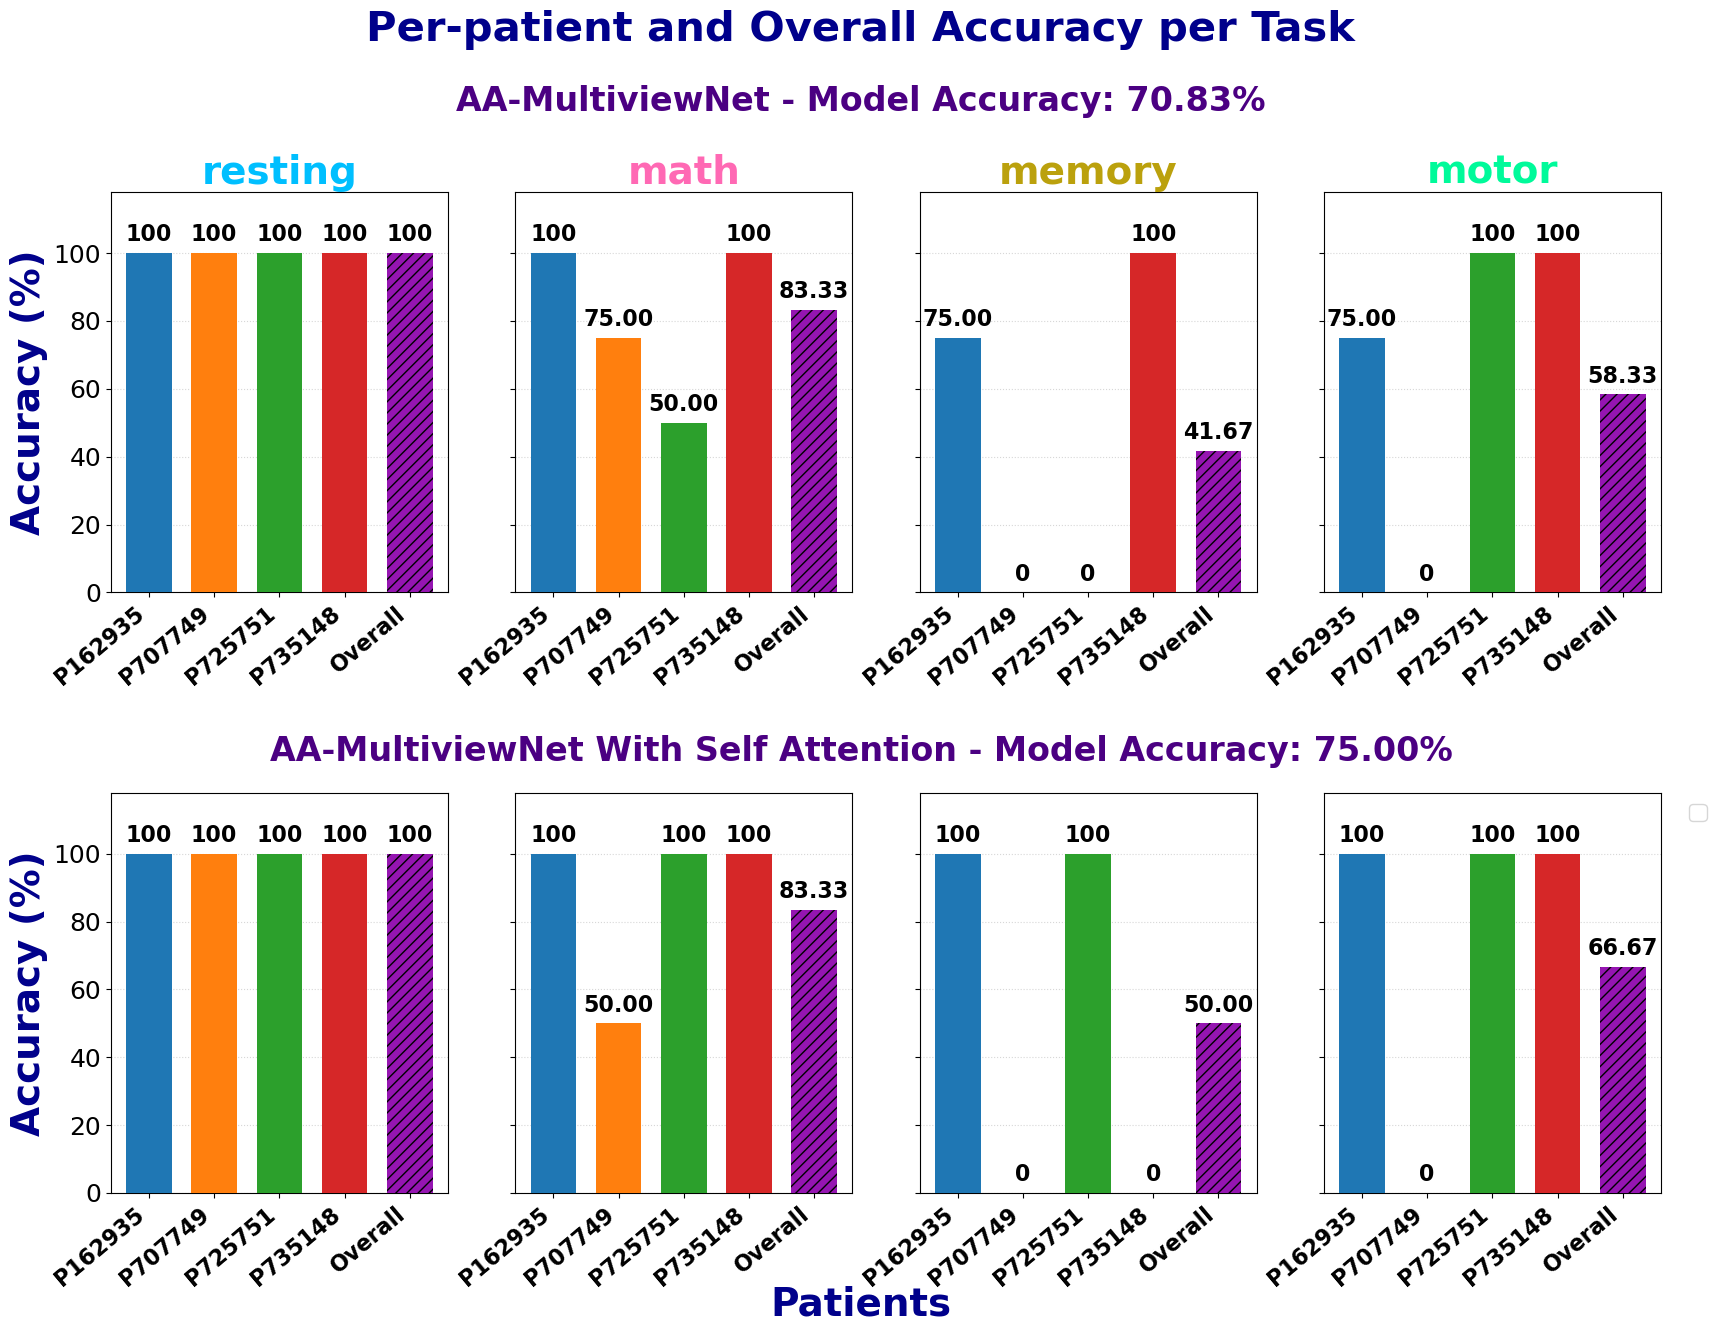

In [ ]:
import matplotlib.pyplot as plt

TASKS = ["resting", "math", "memory", "motor"]

# File paths
cross1_path = rf"{output_dir}\Cross\test_metrics_MultiviewAttention_cross_20250601_122704.csv"
cross2_path = rf"{output_dir}\Cross\test_metrics_MultiviewAttention_cross_20250529_213144.csv"

# Load files
df_cross1 = pd.read_csv(cross1_path)
df_cross2 = pd.read_csv(cross2_path)

def plot_per_patient_accuracy_bars_dual(
    df1, df2, 
    task_names=["resting", "math", "memory", "motor"], 
    style="default", 
    subtitles=["Dataset 1", "Dataset 2"],
    output_path=None
):
    """
    Plots per-patient and overall accuracy per task for two datasets as grouped bar plots in two subplots.
    """
    plt.style.use(style)
    dfs = [df1, df2]
    n_tasks = len(task_names)
    fig, axs = plt.subplots(2, n_tasks, figsize=(5*n_tasks, 13), sharey=True, gridspec_kw={'hspace': 0.5})

    bar_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']
    overall_color = "#9515b1"
    task_title_colors = ['#00bfff', '#ff69b4', "#bba10d", '#00fa9a']

    # Store overall accuracies for subtitles
    overall_accuracies = []

    for row, df in enumerate(dfs):
        # Compute overall accuracy per task
        overall_acc_per_task = df.groupby('y_true').apply(lambda x: (x['y_true'] == x['y_pred']).mean())
        per_patient_acc = df.groupby(['patient_id', 'y_true']).apply(lambda x: (x['y_true'] == x['y_pred']).mean()).unstack(0)
        overall_acc = (df['y_true'] == df['y_pred']).mean()
        overall_accuracies.append(overall_acc)
        tasks = sorted(df['y_true'].unique())
        patients = per_patient_acc.columns.tolist()
        n_bars = len(patients) + 1  # patients + overall

        for t_idx, t in enumerate(tasks):
            ax = axs[row, t_idx]
            # Per-patient bars
            for i, patient in enumerate(patients):
                acc = per_patient_acc[patient].reindex(tasks, fill_value=0)[t] * 100
                if np.isclose(acc, 100) or acc == 0:
                    label = int(acc)
                else:
                    label = f"{acc:.2f}"
                ax.bar(i, acc, color=bar_colors[i % len(bar_colors)], width=0.7, label=f'Patient {patient}' if row == 0 and t_idx == 0 else "", zorder=3)
                ax.text(i, acc + 2, label, ha='center', va='bottom', fontsize=16, color='black', fontweight='bold')
            # Overall bar
            overall = overall_acc_per_task.reindex(tasks, fill_value=0)[t] * 100
            label = f"{int(overall)}" if np.isclose(overall, 100) else f"{overall:.2f}"
            ax.bar(len(patients), overall, color=overall_color, width=0.7, label='Overall' if row == 0 and t_idx == 0 else "", zorder=3, hatch='///')
            ax.text(len(patients), overall + 2, label, ha='center', va='bottom', fontsize=16, color='black', fontweight='bold')
            # Formatting
            if row == 0:
                ax.set_title(task_names[t], fontsize=28, fontweight='bold', color=task_title_colors[t_idx % len(task_title_colors)])
            ax.set_xticks(list(range(n_bars)))
            ax.set_xticklabels([f"P{p}" for p in patients] + ["Overall"], fontsize=16, fontweight='bold', rotation=40, ha='right')
            ax.set_ylim(0, 118)
            ax.grid(axis='y', linestyle=':', alpha=0.5, zorder=0)
            ax.tick_params(axis='y', labelsize=18)
            if t_idx == 0:
                ax.set_ylabel('Accuracy (%)', fontsize=28, fontweight='bold', color='darkblue')
            if row == 1 and t_idx == n_tasks-1:
                ax.legend(fontsize=16, loc='upper left', bbox_to_anchor=(1.05, 1.0))

    # Adjust y positions for better spacing between main title and subtitles
    subtitle_y_positions = [0.95, 0.45]  # Top row, bottom row

    for row, subtitle in enumerate(subtitles):
        fig.text(
            0.5, 
            subtitle_y_positions[row],
            f"{subtitle} - Model Accuracy: {overall_accuracies[row]*100:.2f}%",
            ha='center', va='center',
            fontsize=24, fontweight='bold', color='indigo'
        )

    fig.supxlabel('Patients', fontsize=28, fontweight='bold', color='darkblue')
    fig.suptitle('Per-patient and Overall Accuracy per Task', fontsize=30, fontweight='bold', color='darkblue', y=1.02)
    plt.tight_layout(rect=[0, 0.01, 0.96, 1])
    plt.savefig(f"{output_dir}/per_patient_accuracy_bars_dual.png", dpi=300, bbox_inches='tight')
    plt.show()

# Example usage:
plot_per_patient_accuracy_bars_dual(df_cross1, df_cross2, task_names=TASKS, subtitles=["AA-MultiviewNet", "AA-MultiviewNet With Self Attention"], output_path=None)